In [2]:
import sympy as sp
import numpy as np
import scipy.interpolate as interpolate
import matplotlib.pyplot as plt
from sympy import N

In [3]:
#proef 1 - berekeningen
def pH_buffer(pK, c_b, c_a):
    return pK + sp.log(c_b / c_a, 10)

def capaciteit(dpH, dstof, Vbuff, zuur): #zuur = True of False
    if zuur:
        return - dstof / (dpH * Vbuff)
    elif not zuur:
        return dstof / (dpH * Vbuff)
    
def fout_pH_buffer(pK, c_b, c_a, dpK, dc_b, dc_a):
    pk, cb, ca = sp.symbols('pk cb ca')
    pH = pk + sp.log(cb / ca, 10)
    s_func = sp.sqrt((sp.diff(pH, pk))**2 * dpK**2 + (sp.diff(pH, cb))**2 * dc_b**2 + (sp.diff(pH, ca))**2 * dc_a**2)
    s = s_func.subs([(ca, c_a), (cb, c_b), (pk, pK)])
    return s

def fout_capaciteit(dpH, dstof, Vbuff, ddpH, ddstof, dVbuff):
    dph, Dstof, vbuff = sp.symbols('dph Dstof vbuff')
    cap = Dstof / (dph * vbuff)
    s_func = sp.sqrt((sp.diff(cap, dph))**2 * ddpH**2 + (sp.diff(cap, Dstof))**2 * ddstof**2 + (sp.diff(cap, vbuff))**2 * dVbuff**2)
    s = s_func.subs([(dph, dpH), (Dstof, dstof), (vbuff, Vbuff)])
    return s

In [4]:
#fout op concentratie
def dc(n, V, dn, dV):
    N, v = sp.symbols('N v')
    c = N / v
    s_func = sp.sqrt((sp.diff(c, N))**2 * dn**2 + (sp.diff(c, v))**2 * dV**2)
    s = s_func.subs([(N, n), (v, V)])
    return s

dna = 5e-6 * 1.049 / 60
na = 0.0465 * 100e-3

Va = 100e-3
dVa = 0.1e-3

ca = na / Va
dc_a1 = dc(na ,Va, dna, dVa)

dnb = 0.01 / 82
nb = 0.0535*100e-3

Vb = 100e-3
dVb = 0.1e-3

cb = nb / Vb
dc_b1 = dc(nb, Vb, dnb, dVb)
print(dc_a1, dc_b1)

4.65082161274877e-5 0.00122068515353107


In [5]:
#niks
pK = 4.74
dpK = 0.01 #kan aangepast worden idk

deltapH = 4.77
pH_fout = 0.01 #resolutie, kan aangepast worden
ddeltapH = np.sqrt(4.77**2 * pH_fout**2 + 4.45**2 * pH_fout**2)

Vbuff = 10e-3 #10 mL
dVbuff = 0.1e-3

deltastof = 2e-3 * 0.1 #2 mL * 0.1 mol/L → mol
dstof = 0.05e-3

c_a = 0.0465

c_b = 0.1 - c_a
print(N(pH_buffer(pK, c_b, c_a)), N(fout_pH_buffer(pK, c_b, c_a, dpK, dc_b1, dc_a1)))

4.80090082913128 0.0140847056196745


In [6]:
#HCl → sterk genoeg om ervanuit te gaan dat alle HCl wegreageert → gwn min
def c2(c1, V1, V2):
    conc = c1 * V1 / V2
    return conc

def dc2(c1, V1, V2, dc1, dV1, dV2):
    c, v1, v2 = sp.symbols('c v1 v2')
    c2 = c * v1 / v2
    s_func = sp.sqrt((sp.diff(c2, c))**2 * dc1**2 + (sp.diff(c2, v1))**2 * dV1**2 + (sp.diff(c2, v2))**2 * dV2**2)
    s = s_func.subs([(c, c1), (v1, V1), (v2, V2)])
    return s

pK = 4.74
dpK = 0.01 #kan aangepast worden idk

deltapH = -(4.77 - 4.45)
pH_fout = 0.01 #resolutie, kan aangepast worden
ddeltapH = np.sqrt(4.77**2 * pH_fout**2 + 4.45**2 * pH_fout**2) #propagatie doe je ding!

Vbuff = 10e-3 #10 mL
dVbuff = 0.1e-3

deltastof = 2e-3 * 0.1 #2 mL * 0.1 mol/L → mol
dstof = 0.05e-3

c_a = c2(0.0465, 10e-3, 12e-3)
dc_a = dc2(0.0465, 10e-3, 12e-3, dc_a1, 0.1e-3, 0.1e-3) #random, moet aangepast worden

c_b = c2(0.0535, 10e-3, 12e-3)
dc_b = dc2(0.0535, 10e-3, 12e-3, dc_b1, 0.1e-3, 0.1e-3)

c_HCl = c2(0.1, 2e-3, 12e-3)
dc_HCl = dc2(0.1, 2e-3, 12e-3, 0.001, 0.1e-3, 0.1e-3)

c_a_hcl = c_a + c_HCl
dc_a_hcl = sp.sqrt(c_a**2 * dc_a**2 + c_HCl**2 * dc_HCl**2)

c_b_hcl = c_b - c_HCl
dc_b_hcl = sp.sqrt(c_b**2 * dc_b**2 + c_HCl**2 * dc_HCl**2)

print(N(pH_buffer(pK, c_b_hcl, c_a_hcl)), N(fout_pH_buffer(pK, c_b_hcl, c_a_hcl, dpK, dc_b_hcl, dc_a_hcl)))
print(capaciteit(deltapH, deltastof, Vbuff, True), fout_capaciteit(deltapH, deltastof, Vbuff, ddeltapH, dstof, dVbuff))

4.44222316173374 0.0100372252885365
0.06250000000000012 0.0201709498541239


In [7]:
#NaOH 
pK = 4.74
dpK = 0.0 #kan aangepast worden idk

deltapH = 5.18 - 4.77
pH_fout = 0.01 #resolutie, kan aangepast worden
ddeltapH = np.sqrt(5.18**2 * pH_fout**2 + 4.77**2 * pH_fout**2) #propagatie doe je ding!

Vbuff = 10e-3 #10 mL
dVbuff = 0.1e-3

deltastof = 2e-3 * 0.1 #2 mL * 0.1 mol/L → mol
dstof = 0.05e-3

c_a = c2(0.0465, 10e-3, 12e-3)
dc_a = dc2(0.0465, 10e-3, 12e-3, dc_a1, 0.1e-3, 0.1e-3) #random, moet aangepast worden

c_b = c2(0.0535, 10e-3, 12e-3)
dc_b = dc2(0.0535, 10e-3, 12e-3, dc_b1, 0.1e-3, 0.1e-3)

c_NaOH = c2(0.1, 2e-3, 12e-3)
dc_NaOH = dc2(0.1, 2e-3, 12e-3, 0.001, 0.1e-3, 0.1e-3)

c_a_naoh = c_a - c_NaOH
dc_a_naoh = sp.sqrt(c_a**2 * dc_a**2 + c_NaOH**2 * dc_NaOH**2)

c_b_naoh = c_b + c_NaOH
dc_b_naoh = sp.sqrt(c_b**2 * dc_b**2 + c_NaOH**2 * dc_NaOH**2)

print(N(pH_buffer(pK, c_b_naoh, c_a_naoh)), N(fout_pH_buffer(pK, c_b_naoh, c_a_naoh, dpK, dc_b_hcl, dc_a_hcl)))
print(capaciteit(deltapH, deltastof, Vbuff, False), fout_capaciteit(deltapH, deltastof, Vbuff, ddeltapH, dstof, dVbuff))

5.18304146514739 0.000612953902624371
0.04878048780487804 0.0148036927630329


In [8]:
#proef 2 - berekeningen
#TITRATIECURVE fits

toegevoegde_base = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 9.5, 10, 10.5, 11, 11.5, 12, 12.5, 13, 14, 15, 16, 17, 18, 19, 20]
pH = [2.7, 3.38, 3.68, 3.89, 4.08, 4.25, 4.43, 4.6, 4.83, 5.1, 5.3, 5.61, 6.54, 10.68, 11.28, 11.56, 11.77, 11.92, 12.14, 12.27, 12.38, 12.46, 12.53, 12.62, 12.67]

fit = interpolate.CubicSpline(toegevoegde_base, pH)

X = np.linspace(0, 20, 10000)
Y = fit(X)  #de effectieve fit voor op een grafiek

fit_acc_acc = fit.derivative(nu = 2)
tekenwissel_x = fit_acc_acc.roots() #nulpunten zoeken voor tekenwissel
tekenwissel_y = fit(tekenwissel_x)
print(tekenwissel_x, tekenwissel_y)

[ 4.50197346  5.43254081  6.33817192  8.76868944  9.00385641  9.65191025
 10.05716119 10.7409599  11.41608135 11.8766991  12.46049433 12.75947957
 14.95172949 15.10432366 17.25947753 18.52290302] [ 4.16534728  4.32831302  4.48581664  5.03671553  5.10105143  5.4118505
  5.61507539  8.55665676 11.31691617 11.45984024 11.75882824 11.84771637
 12.26443247 12.28205892 12.4772514  12.57690159]


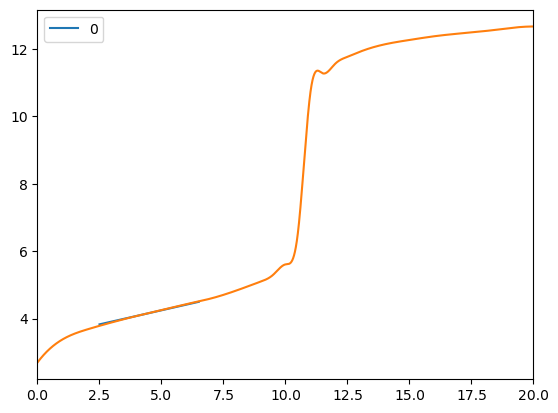

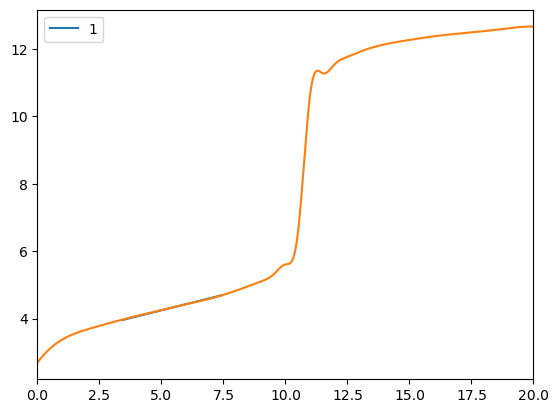

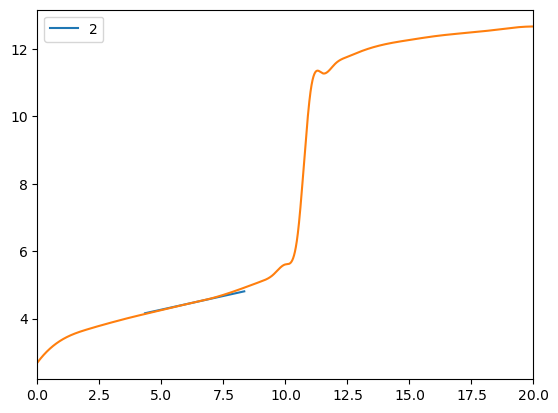

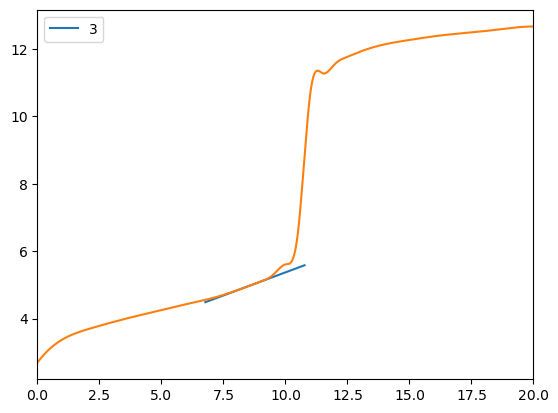

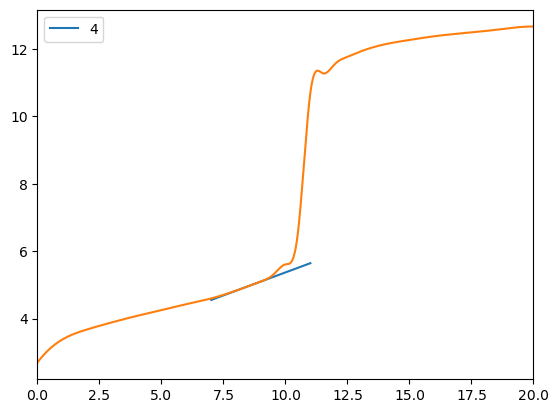

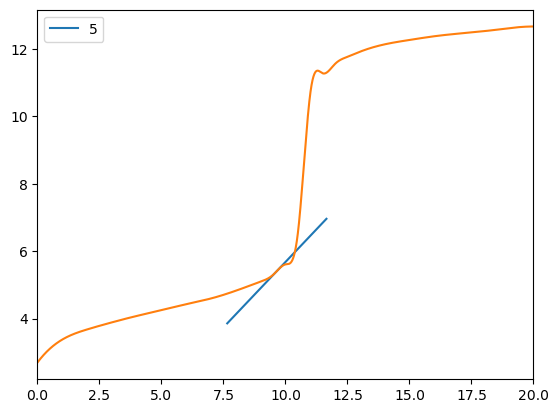

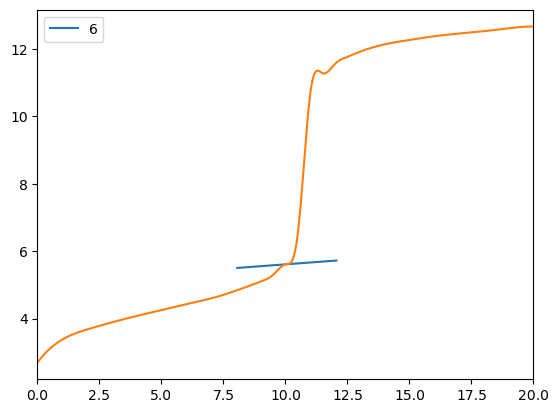

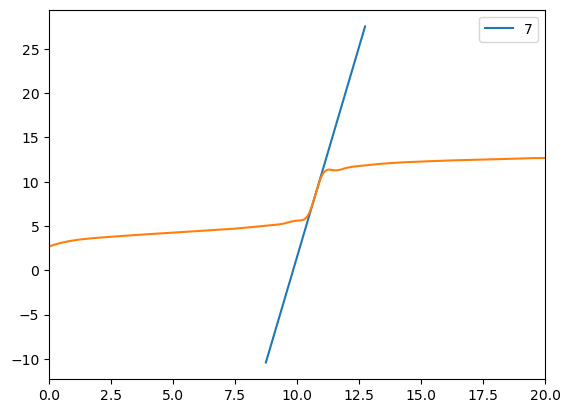

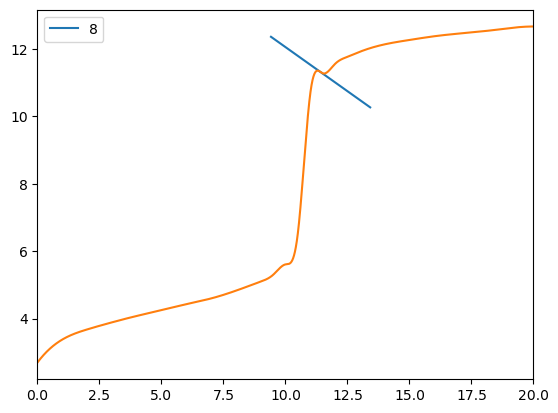

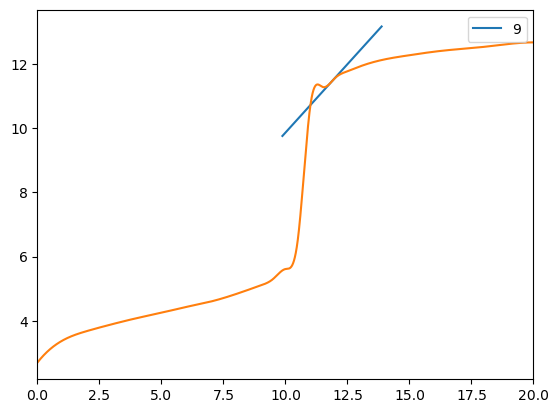

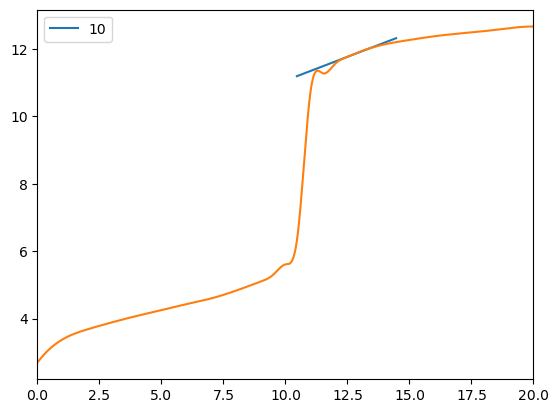

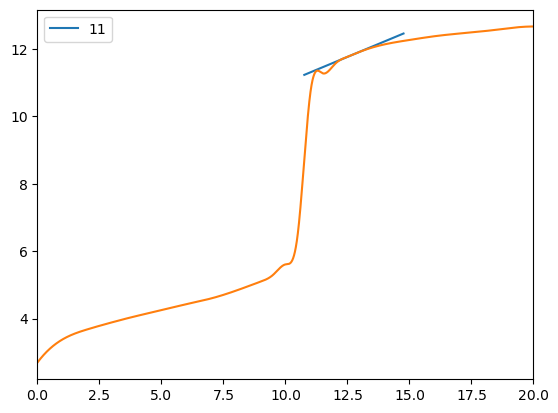

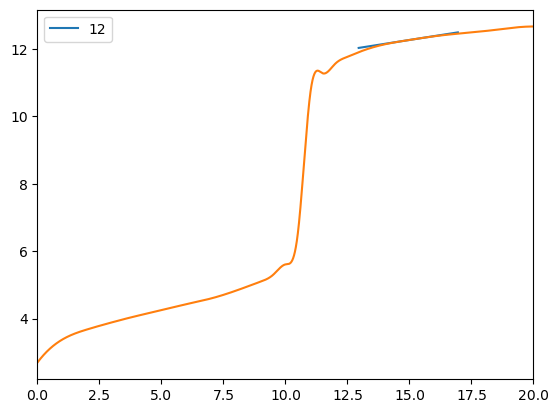

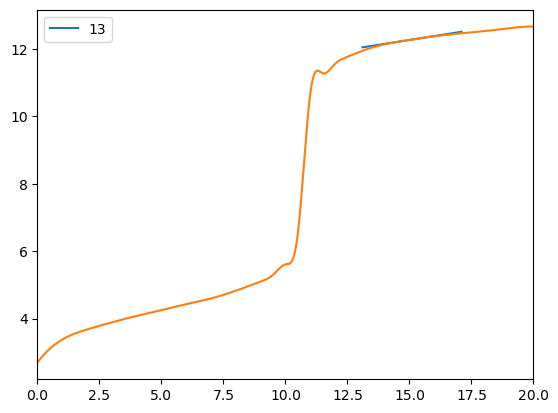

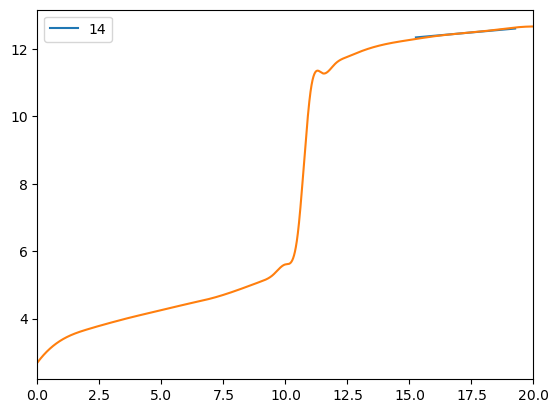

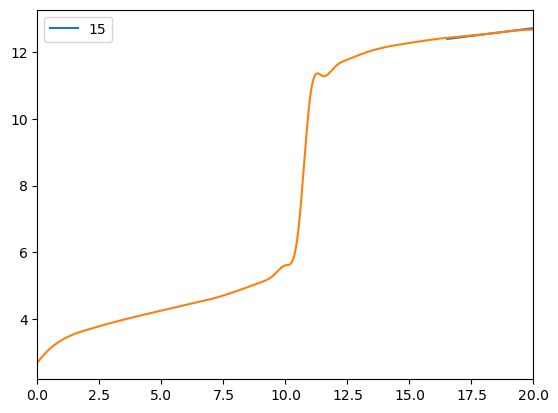

In [9]:
#juiste raaklijn zoeken
for i in range(len(tekenwissel_x)):
    fig, ax = plt.subplots()
    a = fit(tekenwissel_x[i], 1)
    b = tekenwissel_y[i]
    a0 = tekenwissel_x[i]
    x = np.linspace(a0 - 2, a0 +2, 100)
    ax.plot(x, a*(x-a0) + b, label = i)
    ax.plot(X, Y)
    ax.set_xlim(0, 20)
    ax.legend()


In [20]:

#hieruit volgt dat i = 4 en i = 10 de juiste raaklijnen zijn (bekijk pls zelf)
knikpunt1 = tekenwissel_x[4]
knikpunt2 = tekenwissel_x[10]

#rico's
#print(fit(knikpunt1, 1), fit(knikpunt2, 1))
#minimumoppervlakte vinden
x = sp.symbols('x')
interval = np.linspace(knikpunt1, knikpunt2, 2000)
verschillen = [] #alles opslaan voor minimum te zoeken
ricos = []
for i in interval: 
    lood = -fit(i, 1) * (x - i) + fit(i) #telkens de tegengestelde nemen van de rico daar
    int_lood = sp.integrate(lood, (x, knikpunt1, knikpunt2))
    int_titratie = fit.integrate(knikpunt1, knikpunt2) #altijd hetzelfde
    verschillen.append(np.abs(int_titratie - int_lood))
    ricos.append(-fit(i, 1))

10.72144319497925
4.315130108517444
4.013054829686321
4.617520378623683


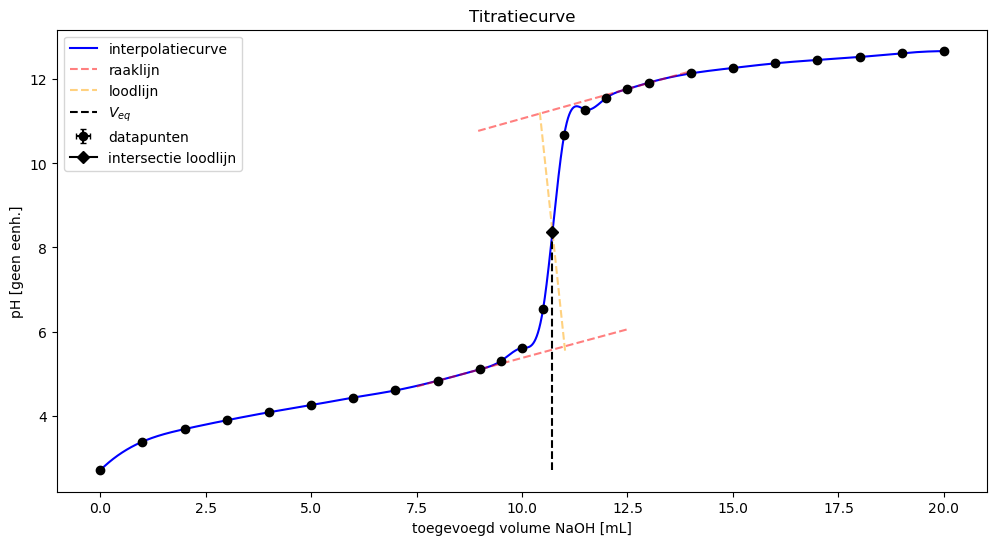

In [21]:
#hier zetten want da duurt megalang
index_min = np.argmin(verschillen)
rico_lood = ricos[index_min]

x_min = index_min * (knikpunt1 + knikpunt2) / 2000 #dit is het omslagpunt
y_min = fit(x_min)
print(x_min)

#alles plotten (geen fouten)
fig, ax = plt.subplots(figsize = (12, 6))
ax.errorbar(toegevoegde_base, pH, marker = 'o', color = 'black', label = 'datapunten', xerr = [0.02 for i in range(len(pH))], yerr = [0.01  for i in range(len(pH))], capsize = 2.5, fmt = " ")
ax.plot(X, Y, color = 'blue', label = 'interpolatiecurve')
rkln1 = np.linspace(knikpunt1 - 1.5, knikpunt1 + 3.5, 20)
ax.plot(rkln1, fit(knikpunt1, 1) * (rkln1 - knikpunt1) + fit(knikpunt1), 'r--', alpha = 0.5)
rkln2 = np.linspace(knikpunt2 - 3.5, knikpunt2 + 1.5, 20)
ax.plot(rkln2, fit(knikpunt2, 1) * (rkln2 - knikpunt2) + fit(knikpunt2), 'r--', label = 'raaklijn', alpha = 0.5)
loodlijn = np.linspace(x_min-0.3, x_min+0.3, 100)
ax.plot(loodlijn, rico_lood * (loodlijn - x_min) + y_min, color = 'orange', ls = '--', label = 'loodlijn', alpha = 0.5)
ax.vlines(x_min, ymin = fit(toegevoegde_base[0]), ymax = fit(x_min), color = 'black', ls = '--', label = r'$V_{eq}$')
ax.errorbar(x_min, y_min, color = 'black', marker = 'D', label = 'intersectie loodlijn')
ax.legend()
ax.set_xlabel(r'toegevoegd volume NaOH [mL]')
ax.set_ylabel('pH [geen eenh.]')
ax.set_title('Titratiecurve')
print(fit(x_min/2))
print(fit(x_min/2 - 1.7283189627571192))
print(fit(x_min/2 + 1.7283189627571192))

In [22]:
#fouten door ruis
print((knikpunt2 - knikpunt1)/2)

1.7283189627571192


In [23]:
#molariteit
def molariteit(M1, V1, V2):
    return M1 * V1 / V2

M1 = 0.1
V1 = x_min * 1e-3 #mL → L
V2 = 40e-3

molar = molariteit(M1, V1, V2)
dmolar = dc2(M1, V1, V2, 0.001, 1.7283189627571192 * 2e-3, 4e-3) #fout op x_min is heel omslaggebied

print(molar, dmolar)

0.026803607987448123 0.00905170361187376


In [24]:
#massaprocent
def fout_mproc(m_az, m_t, dm_t, dm_az):
    Mt, Ma = sp.symbols('Mt Ma')
    proc = Ma / Mt
    s_func = sp.sqrt((sp.diff(proc, Mt))**2 * dm_t**2 + (sp.diff(proc, Ma))**2 * dm_az**2)
    s = s_func.subs([(Ma, m_az), (Mt, m_t)])
    return s

m_tot = 40 * 1.010 #mL * g / mL → g (10x verdund)
m_azijn = molar * 10 * 60.5 #volume azijnzuur * dichtheid
m_procent = m_azijn / m_tot
d_procent = fout_mproc(m_azijn, m_tot, 4e-3 * 0.1010, 1.7283189627571192 * 2 * 1.049e-1) 
print(m_procent, d_procent)
print(m_tot, m_azijn)
print(4*1.010, 1.7283189627571192 * 2 * 1.010)


0.4013906641684682 0.00897528105562585
40.4 16.216182832406115
4.04 3.4912043047693806


In [33]:
#opnieuw
n_naoh = x_min * 1e-3 * 0.1
m_azijn = n_naoh * 60.05
m_tot = 40 * 1.010
print(m_azijn/m_tot * 100)

dn = sp.sqrt((x_min * 1e-3)**2 * 0.001**2 + 0.1**2 * (1.7e-3 * 2)**2)
dm_az = dn * 60.05
dm_tot = 4 * 1.010

print(fout_mproc(m_azijn, m_tot, dm_tot, dm_az) * 100)
print(m_azijn, dm_az)


0.15936204550953068
0.0530141831983294
0.06438226638585039 0.0204271485191276


In [35]:
print(fit(10.6))

7.274321312835246
